# 03 · Hypothesis testing

<sub>Telco churn analysis &nbsp;|&nbsp; 01 Framing · 02 Cleaning & EDA · **03 Hypothesis tests** · 04 Modelling · 05 A/B test & ROI</sub>

**Goal:** test four EDA claims formally, reporting **effect sizes and confidence intervals**, not just p-values.

> **Key findings**
>
> - All four claims hold after Holm correction for multiple testing.
> - Contract (+36 pts) > e-check (+28 pts) > fiber (+23 pts) ≫ price (median +$15, small effect).
> - The fiber gap shrinks but persists within every contract type (Mantel-Haenszel OR 2.55).

> With n ≈ 7,000 almost any difference is "significant", so the **effect size and CI** carry the real information. α = 0.05; Holm correction across the four tests.

In [1]:
import sys, warnings; from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from churn import config as C, style, charts
style.setup()

In [2]:
from churn.data_cleaning import load_clean
from churn import hypothesis_tests as st

df = load_clean()
pct = lambda r: f"{r['effect_size']*100:+.1f} pts [{r['ci_low']*100:.1f}, {r['ci_high']*100:.1f}]"

## H1 · Month-to-month vs. annual contracts

**H₀:** churn is independent of contract type · **Test:** χ² (3 × 2), Cramér's V with bootstrap CI, plus a two-proportion CI for M2M vs. annual.

In [3]:
h1 = st.chi_square(df, "contract")
m2m = df.contract == "Month-to-month"
h1b = st.two_prop(df.churn[m2m].sum(), m2m.sum(), df.churn[~m2m].sum(), (~m2m).sum())
style.card({"χ² (dof 2)": f"{h1['statistic']:,.0f}", "p-value": f"{h1['p_value']:.1e}",
          "Cramér's V": f"{h1['effect_size']:.2f} [{h1['ci_low']:.2f}, {h1['ci_high']:.2f}]",
          "Churn: M2M vs annual": f"{h1b['p1']:.1%} vs {h1b['p2']:.1%}",
          "Difference": pct(h1b), "Risk ratio": f"{h1b['risk_ratio']:.1f}×"}, caption="H1 result")

χ² (dof 2),"1,185"
p-value,5.9e-258
Cramér's V,"0.41 [0.39, 0.43]"
Churn: M2M vs annual,42.7% vs 6.8%
Difference,"+36.0 pts [34.1, 37.7]"
Risk ratio,6.3×


> **Reject H₀.** A strong association (V = 0.41): month-to-month customers churn **36 pts** more, a **6.3× risk ratio**.

## H2 · Do churners pay more?

**H₀:** both groups have the same distribution of monthly charges. First, check normality to pick the test.

In [4]:
churned = df.loc[df.churn == 1, "monthly_charges"].to_numpy()
stayed = df.loc[df.churn == 0, "monthly_charges"].to_numpy()
style.table(st.normality_report({"churned": churned, "stayed": stayed})[["n", "shapiro_W", "shapiro_p", "skew"]],
          fmt={"shapiro_W": "{:.3f}", "shapiro_p": "{:.1e}", "skew": "{:.2f}"}, caption="Normality check")

,n,shapiro_W,shapiro_p,skew
group,,,,
churned,1869,0.928,5.4e-29,-0.73
stayed,5174,0.913,5.7e-47,-0.03


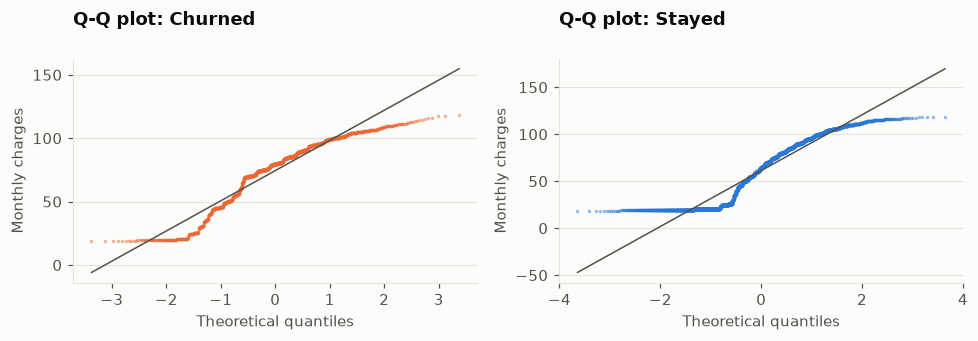

In [5]:
charts.qq_pair(churned, stayed);

Both groups are clearly **non-normal** (the 'stayed' group is bimodal), so the primary test is **Mann-Whitney U**. Welch's t is reported as a robustness check.

In [6]:
h2, h2t = st.mann_whitney(churned, stayed), st.welch_t(churned, stayed)
style.card({"Mann-Whitney p": f"{h2['p_value']:.1e}",
          "Rank-biserial r": f"{h2['effect_size']:.2f}",
          "P(churner pays more)": f"{(h2['effect_size'] + 1) / 2:.0%}",
          "Median difference": f"${h2['median_diff']:.2f} [{h2['ci_low']:.2f}, {h2['ci_high']:.2f}]",
          "Welch t · Cohen's d": f"p = {h2t['p_value']:.1e} · d = {h2t['effect_size']:.2f}"}, caption="H2 result")

Mann-Whitney p,3.3e-54
Rank-biserial r,0.24
P(churner pays more),62%
Median difference,"$15.22 [13.95, 17.65]"
Welch t · Cohen's d,p = 8.6e-73 · d = 0.47


> **Reject H₀**, but the effect is only **small-to-moderate**: a random churner out-pays a random stayer 62 % of the time. Price is part of the story, not the whole of it.

## H3 · Fiber vs. DSL

**H₀:** p(fiber) = p(DSL) · **Test:** two-proportion z, plus Cochran-Mantel-Haenszel **within contract types** to check for confounding.

In [7]:
fib, dsl = df[df.internet_service == "Fiber optic"], df[df.internet_service == "DSL"]
h3 = st.two_prop(fib.churn.sum(), len(fib), dsl.churn.sum(), len(dsl))
sub = df[df.internet_service.isin(["Fiber optic", "DSL"])]
mh = st.mantel_haenszel(sub.internet_service == "Fiber optic", sub.churn, sub.contract)
style.card({"Churn: fiber vs DSL": f"{h3['p1']:.1%} vs {h3['p2']:.1%}", "p-value": f"{h3['p_value']:.1e}",
          "Difference": pct(h3), "Risk ratio": f"{h3['risk_ratio']:.2f}",
          "Crude odds ratio": f"{h3['odds_ratio']:.2f}",
          "MH odds ratio (within contract)": f"{mh['odds_ratio']:.2f} [{mh['ci_low']:.2f}, {mh['ci_high']:.2f}]",
          "Breslow-Day homogeneity p": f"{mh['homogeneity_p']:.2f}"}, caption="H3 result")

Churn: fiber vs DSL,41.9% vs 19.0%
p-value,1.4e-73
Difference,"+22.9 pts [20.6, 25.2]"
Risk ratio,2.21
Crude odds ratio,3.08
MH odds ratio (within contract),"2.55 [2.23, 2.91]"
Breslow-Day homogeneity p,0.37


> **Reject H₀.** Fiber customers churn **23 pts** more. Holding contract fixed shrinks the odds ratio (3.08 → 2.55) but it stays far above 1. Contract mix explains part of the gap, not all of it.

## H4 · Electronic check vs. other payment methods

**H₀:** p(e-check) = p(other) · **Test:** two-proportion z with an odds ratio.

In [8]:
ec = df.payment_method == "Electronic check"
h4 = st.two_prop(df.churn[ec].sum(), ec.sum(), df.churn[~ec].sum(), (~ec).sum())
style.card({"Churn: e-check vs other": f"{h4['p1']:.1%} vs {h4['p2']:.1%}", "p-value": f"{h4['p_value']:.1e}",
          "Difference": pct(h4), "Odds ratio": f"{h4['odds_ratio']:.2f} [{h4['or_ci_low']:.2f}, {h4['or_ci_high']:.2f}]"},
         caption="H4 result")

Churn: e-check vs other,45.3% vs 17.1%
p-value,1.2e-141
Difference,"+28.2 pts [25.9, 30.5]"
Odds ratio,"4.02 [3.60, 4.50]"


## Summary

In [9]:
summary = pd.DataFrame({
    "test": ["χ²", "Mann-Whitney U", "two-proportion z", "two-proportion z"],
    "effect size": [f"Cramér's V {h1['effect_size']:.2f}", f"r = {h2['effect_size']:.2f}",
                    f"Cohen's h {h3['cohens_h']:.2f}", f"OR {h4['odds_ratio']:.2f}"],
    "practical size": [pct(h1b), f"median +${h2['median_diff']:.0f}", pct(h3), pct(h4)],
    "p (raw)": [h1["p_value"], h2["p_value"], h3["p_value"], h4["p_value"]],
}, index=["H1 contract", "H2 monthly charges", "H3 fiber vs DSL", "H4 e-check"])
summary = summary.join(st.holm(summary["p (raw)"].to_dict())[["p_holm", "reject_at_0.05"]])
style.table(summary, fmt={"p (raw)": "{:.1e}", "p_holm": "{:.1e}"}, caption="All four claims survive Holm correction")

,test,effect size,practical size,p (raw),p_holm,reject_at_0.05
H1 contract,χ²,Cramér's V 0.41,"+36.0 pts [34.1, 37.7]",5.9e-258,2.3e-257,True
H2 monthly charges,Mann-Whitney U,r = 0.24,median +$15,3.3e-54,3.3e-54,True
H3 fiber vs DSL,two-proportion z,Cohen's h 0.51,"+22.9 pts [20.6, 25.2]",1.4e-73,2.7e-73,True
H4 e-check,two-proportion z,OR 4.02,"+28.2 pts [25.9, 30.5]",1.2e-141,3.7e-141,True


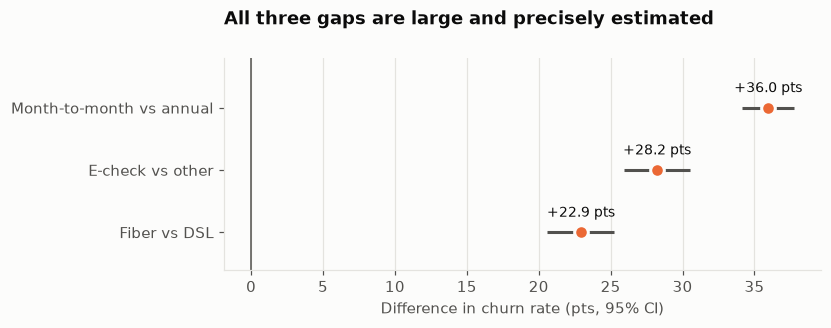

In [10]:
charts.effect_forest(pd.DataFrame({
    "Month-to-month vs annual": [h1b["effect_size"], h1b["ci_low"], h1b["ci_high"]],
    "Fiber vs DSL": [h3["effect_size"], h3["ci_low"], h3["ci_high"]],
    "E-check vs other": [h4["effect_size"], h4["ci_low"], h4["ci_high"]]}, index=["diff", "lo", "hi"]).T);

> **Next:** these are *marginal* effects of overlapping factors, and none is causal. Notebook 04 estimates each one holding the others fixed; notebook 05 designs an experiment to test an intervention.